<a href="https://colab.research.google.com/github/deepak-kumar-da/smart-comment-classifier/blob/main/notebooks/06_model_improvement_and_hyperparameter_tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q iterative-stratification

from google.colab import drive
drive.mount('/content/drive',force_remount=True)

import os
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split,StratifiedKFold,GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score
)

from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit


warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

BASE = "/content/drive/MyDrive/Smart_Comment_Classifier"

PROCESSED = f"{BASE}/datasets/processed"
MODELS = f"{BASE}/models"
OUTPUTS = f"{BASE}/outputs"

TUNED_MODELS = f"{MODELS}/tuned"

os.makedirs(TUNED_MODELS, exist_ok=True)
os.makedirs(OUTPUTS, exist_ok=True)

Mounted at /content/drive


In [3]:
# load datasets

uci = pd.read_csv(
    f"{PROCESSED}/uci_spam_final.csv"
)

jigsaw = pd.read_csv(
    f"{PROCESSED}/jigsaw_toxicity_final.csv"
)

print("UCI:", uci.shape)
print("Jigsaw:", jigsaw.shape)

UCI: (1741, 4)
Jigsaw: (159272, 9)


In [5]:
# toxicity labels

TOXICITY_LABELS = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

assert all(
    col in jigsaw.columns
    for col in TOXICITY_LABELS
)

In [6]:
# spam train-test split

uci["label"] = pd.to_numeric(
    uci["label"],
    errors="coerce"
)

uci = uci.dropna(
    subset=["text", "label"]
).copy()

uci["label"] = uci["label"].astype(int)

X_spam = uci["text"].astype(str)
y_spam = uci["label"]

X_spam_train, X_spam_test, y_spam_train, y_spam_test = (
    train_test_split(
        X_spam,
        y_spam,
        test_size=0.20,
        random_state=42,
        stratify=y_spam
    )
)

print("Spam training:", len(X_spam_train))
print("Spam testing:", len(X_spam_test))

Spam training: 1392
Spam testing: 349


In [7]:
# toxicity train-test split

X_tox = jigsaw["text"].astype(str)

Y_tox = jigsaw[TOXICITY_LABELS].astype(int)

# Original 80/20 test split
splitter = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X_tox, Y_tox)
)

X_tox_train_full = X_tox.iloc[train_idx]
Y_tox_train_full = Y_tox.iloc[train_idx]

X_tox_test = X_tox.iloc[test_idx]
Y_tox_test = Y_tox.iloc[test_idx]

# Split the training portion into training and validation
validation_splitter = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.1875,
    random_state=43
)

core_idx, val_idx = next(
    validation_splitter.split(
        X_tox_train_full,
        Y_tox_train_full
    )
)

X_tox_train = X_tox_train_full.iloc[core_idx]
Y_tox_train = Y_tox_train_full.iloc[core_idx]

X_tox_val = X_tox_train_full.iloc[val_idx]
Y_tox_val = Y_tox_train_full.iloc[val_idx]

print("Training:", len(X_tox_train))
print("Validation:", len(X_tox_val))
print("Testing:", len(X_tox_test))

Training: 103526
Validation: 23891
Testing: 31855


In [8]:
# spam hyperparameter tuning -> 5-fold stratified cross-validation

spam_models_to_tune = {

    "Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer()),
        ("model", MultinomialNB())
    ]),

    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=2000
        ))
    ]),

    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer()),
        ("model", LinearSVC(
            class_weight="balanced"
        ))
    ])
}

In [9]:
# parameter grids

spam_parameter_grids = {

    "Naive Bayes": {
        "tfidf__ngram_range": [(1, 1), (1, 2)],
        "tfidf__min_df": [1, 2],
        "model__alpha": [0.1, 0.5, 1.0]
    },

    "Logistic Regression": {
        "tfidf__ngram_range": [(1, 1), (1, 2)],
        "tfidf__min_df": [1, 2],
        "model__C": [0.5, 1.0, 2.0]
    },

    "Linear SVM": {
        "tfidf__ngram_range": [(1, 1), (1, 2)],
        "tfidf__min_df": [1, 2],
        "model__C": [0.5, 1.0, 2.0]
    }
}

print("Parameter grids prepared.")

Parameter grids prepared.


In [10]:
# GridSearchCV

spam_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

spam_tuned_models = {}
spam_tuning_results = []

for name, pipeline in spam_models_to_tune.items():

    print("\nTuning:", name)

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=spam_parameter_grids[name],
        scoring="f1_macro",
        cv=spam_cv,
        n_jobs=1,
        verbose=1,
        refit=True
    )

    search.fit(
        X_spam_train,
        y_spam_train
    )

    spam_tuned_models[name] = search.best_estimator_

    spam_tuning_results.append({
        "Model": name,
        "Best_CV_Macro_F1": search.best_score_,
        "Best_Parameters": str(search.best_params_)
    })

    print("Best CV F1:", search.best_score_)
    print("Best parameters:", search.best_params_)

spam_tuning_df = pd.DataFrame(
    spam_tuning_results
)

display(spam_tuning_df)


Tuning: Naive Bayes
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best CV F1: 0.9359705861246057
Best parameters: {'model__alpha': 0.5, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}

Tuning: Logistic Regression
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best CV F1: 0.9444487813146576
Best parameters: {'model__C': 2.0, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}

Tuning: Linear SVM
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best CV F1: 0.95032914586903
Best parameters: {'model__C': 2.0, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}


,Model,Best_CV_Macro_F1,Best_Parameters
0,Naive Bayes,0.935971,"{'model__alpha': 0.5, 'tfidf__min_df': 1, 'tfi..."
1,Logistic Regression,0.944449,"{'model__C': 2.0, 'tfidf__min_df': 2, 'tfidf__..."
2,Linear SVM,0.950329,"{'model__C': 2.0, 'tfidf__min_df': 1, 'tfidf__..."


In [11]:
# compare tuned spam models on test data

spam_final_results = []
spam_final_predictions = {}

for name, model in spam_tuned_models.items():

    predictions = model.predict(X_spam_test)

    spam_final_predictions[name] = predictions

    spam_final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_spam_test, predictions
        ),
        "Macro_F1": f1_score(
            y_spam_test,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Spam_Precision": precision_score(
            y_spam_test,
            predictions,
            pos_label=1,
            zero_division=0
        ),
        "Spam_Recall": recall_score(
            y_spam_test,
            predictions,
            pos_label=1,
            zero_division=0
        ),
        "Spam_F1": f1_score(
            y_spam_test,
            predictions,
            pos_label=1,
            zero_division=0
        )
    })

spam_final_df = pd.DataFrame(spam_final_results)

display(
    spam_final_df.sort_values(
        "Macro_F1",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Macro_F1,Spam_Precision,Spam_Recall,Spam_F1
1,Logistic Regression,0.9570,0.9568,0.9873,0.9226,0.9538
2,Linear SVM,0.9484,0.9483,0.9630,0.9286,0.9455
0,Naive Bayes,0.9341,0.9340,0.9394,0.9226,0.9309


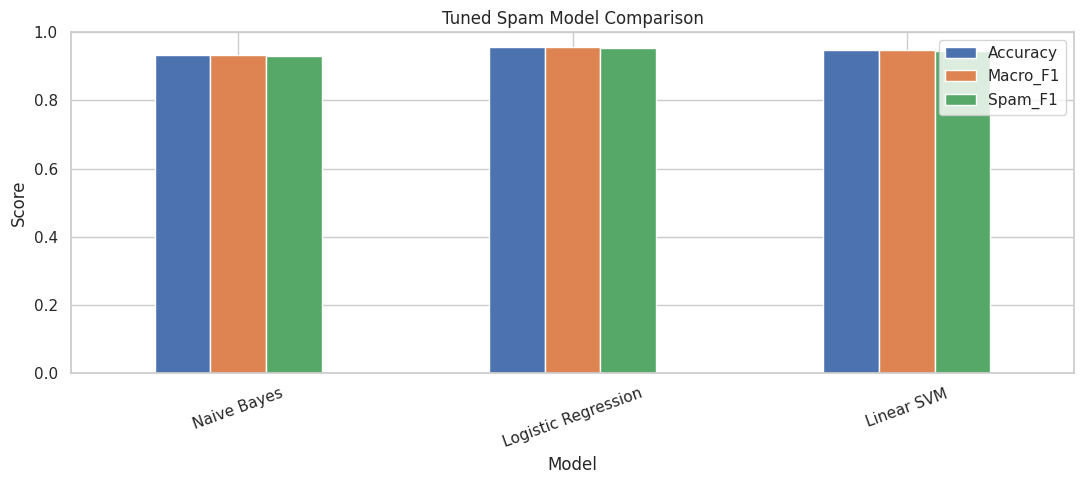

In [12]:
# spam tuning comparison

spam_final_df.set_index("Model")[
    ["Accuracy", "Macro_F1", "Spam_F1"]
].plot(
    kind="bar",
    figsize=(11, 5),
    ylim=(0, 1)
)

plt.title("Tuned Spam Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(
    f"{OUTPUTS}/notebook06_spam_tuning_comparison.png",
    dpi=300
)
plt.show()

In [13]:
# fit toxicity tf-idf

toxicity_vectorizer_tuned = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=200000
)

X_tox_train_vec = toxicity_vectorizer_tuned.fit_transform(
    X_tox_train
)

X_tox_val_vec = toxicity_vectorizer_tuned.transform(
    X_tox_val
)

X_tox_test_vec = toxicity_vectorizer_tuned.transform(
    X_tox_test
)

print("Training:", X_tox_train_vec.shape)
print("Validation:", X_tox_val_vec.shape)
print("Testing:", X_tox_test_vec.shape)

Training: (103526, 200000)
Validation: (23891, 200000)
Testing: (31855, 200000)


In [14]:
# define toxicity models

toxicity_candidates = {

    "Naive Bayes": {
        "factory": lambda alpha: OneVsRestClassifier(
            MultinomialNB(alpha=alpha)
        ),
        "parameters": [0.1, 0.5, 1.0],
        "parameter_name": "alpha"
    },

    "Logistic Regression": {
        "factory": lambda c: OneVsRestClassifier(
            LogisticRegression(
                C=c,
                class_weight="balanced",
                max_iter=1500
            )
        ),
        "parameters": [0.5, 1.0, 2.0],
        "parameter_name": "C"
    },

    "Linear SVM": {
        "factory": lambda c: OneVsRestClassifier(
            LinearSVC(
                C=c,
                class_weight="balanced"
            )
        ),
        "parameters": [0.5, 1.0, 2.0],
        "parameter_name": "C"
    }
}

print("Toxicity tuning candidates ready.")

Toxicity tuning candidates ready.


In [15]:
# tuning toxicity model

toxicity_tuned_models = {}
toxicity_tuning_results = []

for name, config in toxicity_candidates.items():

    best_score = -1
    best_model = None
    best_parameter = None

    print("\nTuning:", name)

    for parameter in config["parameters"]:

        print(
            config["parameter_name"],
            "=",
            parameter
        )

        model = config["factory"](parameter)

        model.fit(
            X_tox_train_vec,
            Y_tox_train
        )

        predictions = model.predict(
            X_tox_val_vec
        )

        score = f1_score(
            Y_tox_val,
            predictions,
            average="macro",
            zero_division=0
        )

        print("Validation macro F1:", round(score, 4))

        if score > best_score:

            best_score = score
            best_model = model
            best_parameter = parameter

    toxicity_tuned_models[name] = best_model

    toxicity_tuning_results.append({
        "Model": name,
        "Best_Parameter": best_parameter,
        "Validation_Macro_F1": best_score
    })

toxicity_tuning_df = pd.DataFrame(
    toxicity_tuning_results
)

display(toxicity_tuning_df)


Tuning: Naive Bayes
alpha = 0.1
Validation macro F1: 0.4219
alpha = 0.5
Validation macro F1: 0.2365
alpha = 1.0
Validation macro F1: 0.1532

Tuning: Logistic Regression
C = 0.5
Validation macro F1: 0.5517
C = 1.0
Validation macro F1: 0.5662
C = 2.0
Validation macro F1: 0.5937

Tuning: Linear SVM
C = 0.5
Validation macro F1: 0.6215
C = 1.0
Validation macro F1: 0.6163
C = 2.0
Validation macro F1: 0.6009


,Model,Best_Parameter,Validation_Macro_F1
0,Naive Bayes,0.1,0.421865
1,Logistic Regression,2.0,0.593716
2,Linear SVM,0.5,0.621476


In [16]:
# decision threshold optimization

def get_model_scores(model, X):

    if hasattr(model, "predict_proba"):

        scores = model.predict_proba(X)

    elif hasattr(model, "decision_function"):

        scores = model.decision_function(X)

    else:

        raise ValueError(
            "Model has no probability or decision function."
        )

    scores = np.asarray(scores)

    if scores.ndim == 1:
        scores = scores.reshape(-1, 1)

    return scores


toxicity_validation_scores = {}

for name, model in toxicity_tuned_models.items():

    toxicity_validation_scores[name] = get_model_scores(
        model,
        X_tox_val_vec
    )

    print(
        name,
        toxicity_validation_scores[name].shape
    )

Naive Bayes (23891, 6)
Logistic Regression (23891, 6)
Linear SVM (23891, 6)


In [17]:
def optimize_thresholds(y_true, scores):

    thresholds = []

    for i in range(y_true.shape[1]):

        label_true = y_true.iloc[:, i].values
        label_scores = scores[:, i]

        candidates = np.unique(
            np.quantile(
                label_scores,
                np.linspace(0.05, 0.95, 41)
            )
        )

        # Include conventional defaults as candidates
        candidates = np.unique(
            np.append(candidates, [0.0, 0.5])
        )

        best_threshold = 0.5
        best_f1 = -1

        for threshold in candidates:

            predictions = (
                label_scores >= threshold
            ).astype(int)

            score = f1_score(
                label_true,
                predictions,
                zero_division=0
            )

            if score > best_f1:

                best_f1 = score
                best_threshold = threshold

        thresholds.append(best_threshold)

    return np.array(thresholds)


toxicity_thresholds = {}

for name, scores in toxicity_validation_scores.items():

    toxicity_thresholds[name] = optimize_thresholds(
        Y_tox_val,
        scores
    )

    print("\n", name)

    for label, threshold in zip(
        TOXICITY_LABELS,
        toxicity_thresholds[name]
    ):

        print(label, ":", round(float(threshold), 4))


 Naive Bayes
toxic : 0.283
severe_toxic : 0.5
obscene : 0.2845
threat : 0.0004
insult : 0.2584
identity_hate : 0.0041

 Logistic Regression
toxic : 0.6437
severe_toxic : 0.5
obscene : 0.7075
threat : 0.5
insult : 0.7513
identity_hate : 0.5

 Linear SVM
toxic : 0.0694
severe_toxic : 0.0
obscene : 0.0
threat : 0.0
insult : 0.1441
identity_hate : 0.0


In [18]:
# evaluation

toxicity_threshold_results = []
toxicity_test_predictions = {}

for name, model in toxicity_tuned_models.items():

    test_scores = get_model_scores(
        model,
        X_tox_test_vec
    )

    thresholds = toxicity_thresholds[name]

    predictions = (
        test_scores >= thresholds.reshape(1, -1)
    ).astype(int)

    toxicity_test_predictions[name] = predictions

    default_predictions = model.predict(
        X_tox_test_vec
    )

    default_f1 = f1_score(
        Y_tox_test,
        default_predictions,
        average="macro",
        zero_division=0
    )

    tuned_f1 = f1_score(
        Y_tox_test,
        predictions,
        average="macro",
        zero_division=0
    )

    toxicity_threshold_results.append({
        "Model": name,
        "Default_Test_Macro_F1": default_f1,
        "Optimized_Test_Macro_F1": tuned_f1
    })

toxicity_threshold_df = pd.DataFrame(
    toxicity_threshold_results
)

display(toxicity_threshold_df.round(4))

,Model,Default_Test_Macro_F1,Optimized_Test_Macro_F1
0,Naive Bayes,0.4106,0.4423
1,Logistic Regression,0.5975,0.6078
2,Linear SVM,0.6082,0.6087


In [19]:
# per label toxicity performance

toxicity_per_label_results = []

for name, predictions in toxicity_test_predictions.items():

    for i, label in enumerate(TOXICITY_LABELS):

        toxicity_per_label_results.append({

            "Model": name,
            "Label": label,

            "Precision": precision_score(
                Y_tox_test.iloc[:, i],
                predictions[:, i],
                zero_division=0
            ),

            "Recall": recall_score(
                Y_tox_test.iloc[:, i],
                predictions[:, i],
                zero_division=0
            ),

            "F1": f1_score(
                Y_tox_test.iloc[:, i],
                predictions[:, i],
                zero_division=0
            )
        })

toxicity_per_label_df = pd.DataFrame(
    toxicity_per_label_results
)

display(
    toxicity_per_label_df.round(4)
)

,Model,Label,Precision,Recall,F1
0,Naive Bayes,toxic,0.7268,0.7065,0.7165
1,Naive Bayes,severe_toxic,0.5610,0.2177,0.3136
2,Naive Bayes,obscene,0.7290,0.6752,0.7011
3,Naive Bayes,threat,0.0402,0.6596,0.0758
4,Naive Bayes,insult,0.6649,0.6458,0.6552
5,Naive Bayes,identity_hate,0.1133,0.6201,0.1916
6,Logistic Regression,toxic,0.7745,0.7608,0.7676
7,Logistic Regression,severe_toxic,0.3248,0.8013,0.4622
8,Logistic Regression,obscene,0.8285,0.7876,0.8076
9,Logistic Regression,threat,0.3812,0.6489,0.4803


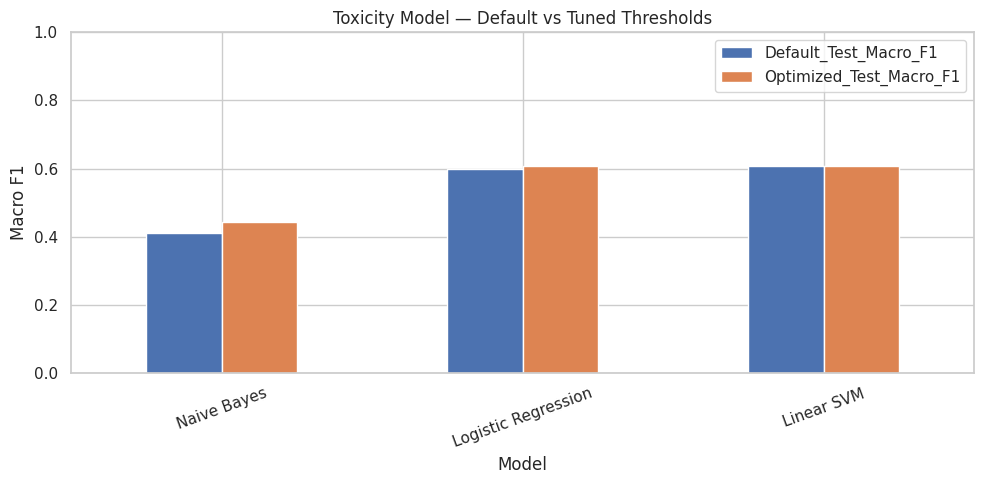

In [20]:
# toxicity improvement

toxicity_threshold_df.set_index("Model")[
    [
        "Default_Test_Macro_F1",
        "Optimized_Test_Macro_F1"
    ]
].plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1)
)

plt.title("Toxicity Model — Default vs Tuned Thresholds")
plt.ylabel("Macro F1")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    f"{OUTPUTS}/notebook06_toxicity_threshold_comparison.png",
    dpi=300
)

plt.show()

In [22]:
# save spam models

joblib.dump(spam_tuned_models, f"{TUNED_MODELS}/spam_tuned_pipelines.pkl")

['/content/drive/MyDrive/Smart_Comment_Classifier/models/tuned/spam_tuned_pipelines.pkl']

In [23]:
# save toxicity models and vectorizer

joblib.dump(toxicity_vectorizer_tuned,f"{TUNED_MODELS}/toxicity_tuned_vectorizer.pkl")
joblib.dump(toxicity_tuned_models, f"{TUNED_MODELS}/toxicity_tuned_models.pkl")
joblib.dump(toxicity_thresholds, f"{TUNED_MODELS}/toxicity_optimized_thresholds.pkl")

['/content/drive/MyDrive/Smart_Comment_Classifier/models/tuned/toxicity_optimized_thresholds.pkl']

In [24]:
# save experiment report

spam_tuning_df.to_csv(
    f"{OUTPUTS}/notebook06_spam_cv_results.csv",
    index=False
)

spam_final_df.to_csv(
    f"{OUTPUTS}/notebook06_spam_test_results.csv",
    index=False
)

toxicity_tuning_df.to_csv(
    f"{OUTPUTS}/notebook06_toxicity_validation_results.csv",
    index=False
)

toxicity_threshold_df.to_csv(
    f"{OUTPUTS}/notebook06_toxicity_test_results.csv",
    index=False
)

toxicity_per_label_df.to_csv(
    f"{OUTPUTS}/notebook06_toxicity_per_label_results.csv",
    index=False
)

with open(
    f"{OUTPUTS}/notebook06_thresholds.json",
    "w"
) as f:

    json.dump(
        {
            name: {
                label: float(threshold)
                for label, threshold in zip(
                    TOXICITY_LABELS,
                    values
                )
            }
            for name, values in toxicity_thresholds.items()
        },
        f,
        indent=4
    )

print("Experiment reports saved.")

Experiment reports saved.


In [25]:
# summary

print("=" * 70)
print("SMART COMMENT CLASSIFIER")
print("NOTEBOOK 06 — FINAL SUMMARY")
print("=" * 70)

print("\nSPAM — TUNED TEST RESULTS")
display(
    spam_final_df.sort_values(
        "Macro_F1",
        ascending=False
    ).round(4)
)

print("\nTOXICITY — TUNED TEST RESULTS")
display(
    toxicity_threshold_df.sort_values(
        "Optimized_Test_Macro_F1",
        ascending=False
    ).round(4)
)

print("\nTOXICITY — INDIVIDUAL LABEL RESULTS")
display(
    toxicity_per_label_df.round(4)
)

print("\nTuned artifacts saved at:")
print(TUNED_MODELS)

print("\nExperiment reports saved at:")
print(OUTPUTS)

SMART COMMENT CLASSIFIER
NOTEBOOK 06 — FINAL SUMMARY

SPAM — TUNED TEST RESULTS


,Model,Accuracy,Macro_F1,Spam_Precision,Spam_Recall,Spam_F1
1,Logistic Regression,0.9570,0.9568,0.9873,0.9226,0.9538
2,Linear SVM,0.9484,0.9483,0.9630,0.9286,0.9455
0,Naive Bayes,0.9341,0.9340,0.9394,0.9226,0.9309



TOXICITY — TUNED TEST RESULTS


,Model,Default_Test_Macro_F1,Optimized_Test_Macro_F1
2,Linear SVM,0.6082,0.6087
1,Logistic Regression,0.5975,0.6078
0,Naive Bayes,0.4106,0.4423



TOXICITY — INDIVIDUAL LABEL RESULTS


,Model,Label,Precision,Recall,F1
0,Naive Bayes,toxic,0.7268,0.7065,0.7165
1,Naive Bayes,severe_toxic,0.5610,0.2177,0.3136
2,Naive Bayes,obscene,0.7290,0.6752,0.7011
3,Naive Bayes,threat,0.0402,0.6596,0.0758
4,Naive Bayes,insult,0.6649,0.6458,0.6552
5,Naive Bayes,identity_hate,0.1133,0.6201,0.1916
6,Logistic Regression,toxic,0.7745,0.7608,0.7676
7,Logistic Regression,severe_toxic,0.3248,0.8013,0.4622
8,Logistic Regression,obscene,0.8285,0.7876,0.8076
9,Logistic Regression,threat,0.3812,0.6489,0.4803



Tuned artifacts saved at:
/content/drive/MyDrive/Smart_Comment_Classifier/models/tuned

Experiment reports saved at:
/content/drive/MyDrive/Smart_Comment_Classifier/outputs
